![](img/banner.png)

# Learning Vector Quantization (LVQ)

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad

## Where this page sits

Chapter 13 of {cite}`hastie2009esl` is about **prototype methods**: instead of
fitting a parametric model, keep a small set of points in feature space and
classify by proximity to them. The chapter develops three of them in turn:

| method | prototypes are placed using | supervision |
|---|---|---|
| K-means clustering (§13.2.1) | the geometry of each class separately | labels used only *after* clustering |
| **LVQ** (§13.2.2) | the geometry of *all* classes at once | labels used *during* training |
| Gaussian mixtures (§13.2.3) | a density model per class | soft, likelihood based |

This page follows §13.2.2. It states the classifier, gives the algorithm
(Algorithm 13.1 of the book), implements it from scratch in a few lines of NumPy,
and compares the prototypes it produces with the ones K-means produces on the
same data — the comparison the book makes in Figure 13.1.

### What you should be able to do at the end

* state the nearest-prototype classifier and say what the prototypes are;
* write the LVQ1 update rule from memory and explain the sign of the two
  branches (attract / repel);
* explain why the learning rate has to go to zero, and why K-means prototypes
  are a good *starting* point;
* describe how K-means prototypes differ from LVQ prototypes in a picture, and
  why the difference is a consequence of who "has a say" in placing them;
* name the price the method pays for being defined by an algorithm rather than
  by the minimisation of a criterion.

## 1. The nearest-prototype classifier

Fix a number of prototypes per class, `R`, and let `K` be the number of classes.
Training produces `K*R` prototypes `m_1, ..., m_{K*R}`, each carrying a class
label `c_j`. A new point `x` is classified by the label of the closest
prototype:

$$
\hat G(x) = c_{j^*}, \qquad j^* = \arg\min_{j=1,\dots,KR} \lVert x - m_j \rVert .
$$

Two things make this attractive for teaching and for practice: the decision
boundary can be arbitrarily curved (it is a union of Voronoi cells), and the
model is just a list of points, so it can be drawn, stored and explained.
Everything difficult is in the question *where to put the prototypes*, and that
is where the methods differ.

The book standardises the features to mean 0 and variance 1 before using
Euclidean distance (p. 461), and so do we.

## 2. The problem that LVQ is answering

The straightforward recipe of §13.2.1 is: cluster the training data of **each
class separately** with `R` centres, keep all centres, and classify by the
nearest one. It works, and it has a visible weakness that the book points out
(p. 462):

> … prototypes are near the class boundaries, leading to potential
> misclassification errors for points near these boundaries. This results from
> an obvious shortcoming with this method: **for each class, the other classes
> do not have a say in the positioning of the prototypes for that class.**

A prototype computed inside one class has no idea that another class is nearby,
so it is happy to sit on the frontier. LVQ fixes exactly this: the update rule
sees the label of the training point *and* the label of the nearest prototype,
so a prototype that is winning points of the wrong class is pushed **away**.

## 3. A simulated three-class problem

To see the difference we need data where the classes touch, since with
well-separated classes every method looks the same. We use the simulation of
ESL §2.3.3 — the one behind Figure 13.1 — with three classes instead of two:

* three classes, two features;
* each class has **10 means**, drawn from a normal distribution centred at a
  **class-specific** location — `(1.5,0)`, `(0,1.5)` and `(1.5,1.5)` — with
  covariance `I/4`;
* each observation is generated by picking one of the ten means at random
  (probability `1/10`) and adding Gaussian noise with covariance `I/5`.

This is the "model somewhere between the two scenarios" of p. 16: the classes
are neither linearly separable nor far apart, and the Bayes boundary is
genuinely curved. The spread of the ten means (`I/4`) is narrower than the book's
`I`, which keeps the problem hard without making it hopeless: even a good rule
errs on a sizeable fraction of the points, but nothing like the two-in-three of
a coin toss among three classes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from skimage import data
from skimage.color import rgb2gray
from skimage.util import view_as_blocks

%matplotlib inline
COLORS = np.array(["tab:blue", "tab:orange", "tab:green"])

In [2]:
def make_mixture(n_per_class=100, n_means=10, seed=0):
    """ESL section 2.3.3 simulation, extended to three classes (Figure 13.1).

    Each class owns ten means, drawn around that class's own centre with
    covariance I/4; every observation is one mean plus N(0, I/5) noise.
    """
    rng = np.random.default_rng(seed)
    centres = np.array([[1.5, 0.0], [0.0, 1.5], [1.5, 1.5]])   # one per class
    X, y = [], []
    for k in range(3):
        means = centres[k] + rng.normal(scale=0.5, size=(n_means, 2))  # 10 means
        pick = rng.integers(0, n_means, size=n_per_class)      # one mean per observation
        noise = rng.normal(scale=np.sqrt(1 / 5), size=(n_per_class, 2))
        X.append(means[pick] + noise)
        y.append(np.full(n_per_class, k))
    return np.vstack(X), np.concatenate(y)


def standardize(X_train, *others):
    """Standardise with the statistics of the training set only."""
    mu, sd = X_train.mean(axis=0), X_train.std(axis=0)
    return [(Z - mu) / sd for Z in (X_train, *others)]


X_train, y_train = make_mixture(seed=0)
X_test, y_test = make_mixture(seed=1)          # same distribution, new sample
X_train, X_test = standardize(X_train, X_test)  # scale with training statistics
X_train.shape, np.bincount(y_train)

((300, 2), array([100, 100, 100]))

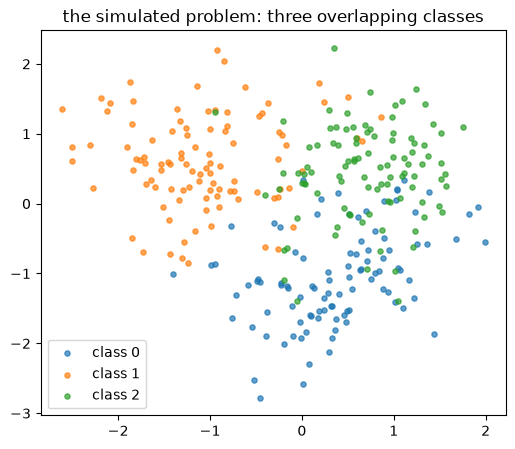

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
for k in range(3):
    ax.scatter(X_train[y_train == k, 0], X_train[y_train == k, 1],
               s=14, color=COLORS[k], alpha=0.7, label=f"class {k}")
ax.set_title("the simulated problem: three overlapping classes")
ax.legend();

## 4. K-means prototypes (the starting point)

`R = 5` prototypes per class, produced by clustering the points of each class
separately. Every prototype inherits the label of the class it was computed in.

prototypes: (15, 2)


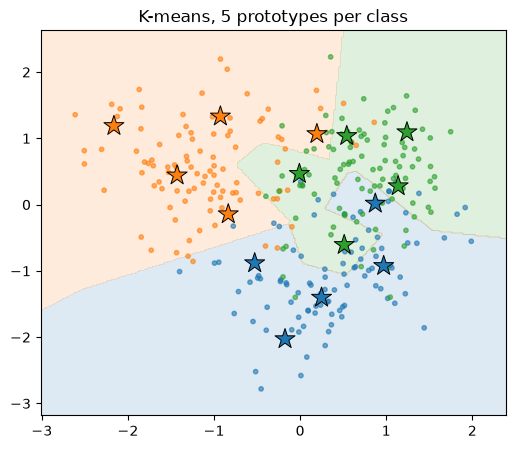

In [4]:
def kmeans_prototypes(X, y, R=5, seed=0):
    """R centres per class: ESL section 13.2.1."""
    protos, pclass = [], []
    for k in np.unique(y):
        km = KMeans(n_clusters=R, n_init=10, random_state=seed).fit(X[y == k])
        protos.append(km.cluster_centers_)
        pclass.append(np.full(R, k))
    return np.vstack(protos), np.concatenate(pclass)


def predict(X, protos, pclass):
    """Nearest-prototype classifier: the label of the closest prototype."""
    d = ((X[:, None, :] - protos[None, :, :]) ** 2).sum(axis=2)
    return pclass[d.argmin(axis=1)]


def plot_regions(ax, protos, pclass, X, y, title):
    pad = 0.4
    xs = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300)
    ys = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300)
    xx, yy = np.meshgrid(xs, ys)
    zz = predict(np.c_[xx.ravel(), yy.ravel()], protos, pclass).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], colors=COLORS, alpha=0.15)
    ax.scatter(X[:, 0], X[:, 1], c=COLORS[y], s=10, alpha=0.6)
    ax.scatter(protos[:, 0], protos[:, 1], c=COLORS[pclass], marker="*",
               s=230, edgecolor="black", linewidth=0.7)
    ax.set_title(title)


protos_km, class_km = kmeans_prototypes(X_train, y_train, R=5)
print("prototypes:", protos_km.shape)
fig, ax = plt.subplots(figsize=(6, 5))
plot_regions(ax, protos_km, class_km, X_train, y_train, "K-means, 5 prototypes per class");

## 5. The LVQ algorithm

**Algorithm 13.1 (Learning Vector Quantization — LVQ)**, as printed in
{cite}`hastie2009esl`, p. 462

1. Choose `R` initial prototypes for each class
   `m_1^(k), ..., m_R^(k)`, `k = 1..K` — for example by sampling `R` training
   points at random from each class, or by running K-means on each class.
2. Sample a training point `x_i` at random (with replacement), and let `(j,k)`
   index the closest prototype `m_j^(k)` to `x_i`.
   * **(a)** If `g_i = k` — the same class — **move the prototype towards** the
     training point:
     $$ m_j^{(k)} \leftarrow m_j^{(k)} + \varepsilon\,(x_i - m_j^{(k)}) $$
   * **(b)** If `g_i != k` — a different class — **move the prototype away**
     from the training point:
     $$ m_j^{(k)} \leftarrow m_j^{(k)} - \varepsilon\,(x_i - m_j^{(k)}) $$
3. Repeat step 2, **decreasing the learning rate `ε` with each iteration towards
   zero**.

Three remarks that the book makes next:

* LVQ is an **online** algorithm: observations arrive one at a time, and each one
  updates a single prototype.
* The decay of `ε` must obey the stochastic-approximation conditions of §11.4
  (`ε_t -> 0`, `sum ε_t = infinity`, `sum ε_t^2 < infinity`); a schedule such as
  `ε_t = ε_0 / (1 + t)` satisfies them.
* The procedure above is **LVQ1**; variants (LVQ2, LVQ3) exist. A drawback of the
  whole family is that they are **defined by an algorithm rather than by the
  minimisation of a fixed criterion**, which makes their properties harder to
  analyse. Newer cost-function-based versions (generalised LVQ) were invented
  precisely to repair this.

The book also uses the K-means solution as the starting values, and gets the
result shown in its Figure 13.1 (lower panel): the prototypes have **moved away
from the decision boundaries** and away from prototypes of competing classes.

In [5]:
def lvq1(X, y, protos, pclass, epochs=150, eps0=0.1, seed=0):
    """Online LVQ1, as Algorithm 13.1 of ESL."""
    m, c = protos.copy(), pclass.copy()
    rng = np.random.default_rng(seed)
    errors = []

    for epoch in range(epochs):
        eps = eps0 / (1.0 + epoch)              # step 3: eps -> 0 as 1/t
        for i in rng.permutation(len(X)):       # step 2: sample a point at random
            x = X[i]
            j = ((m - x) ** 2).sum(axis=1).argmin()   # the closest prototype
            if c[j] == y[i]:
                m[j] += eps * (x - m[j])        # (a) same class    -> attract
            else:
                m[j] -= eps * (x - m[j])        # (b) other class   -> repel
        errors.append((predict(X, m, c) != y).mean())

    return m, c, errors

training error before LVQ: 0.240
training error after  LVQ: 0.170


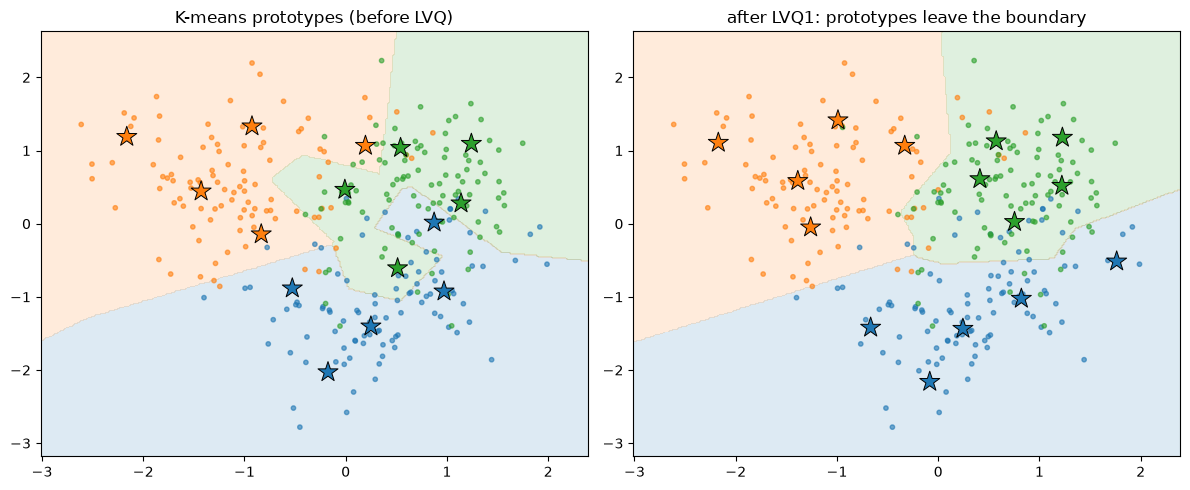

In [6]:
protos_lvq, class_lvq, errors = lvq1(X_train, y_train, protos_km, class_km)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_regions(axes[0], protos_km, class_km, X_train, y_train,
             "K-means prototypes (before LVQ)")
plot_regions(axes[1], protos_lvq, class_lvq, X_train, y_train,
             "after LVQ1: prototypes leave the boundary")
plt.tight_layout()
print(f"training error before LVQ: {(predict(X_train, protos_km, class_km) != y_train).mean():.3f}")
print(f"training error after  LVQ: {(predict(X_train, protos_lvq, class_lvq) != y_train).mean():.3f}")

Look at the stars in the two panels. In the left one several prototypes sit
inside the territory of another colour; in the right one they have been pulled
into their own region and pushed away from the frontier. That is the whole
effect of the sign in step 2, repeated a few thousand times.

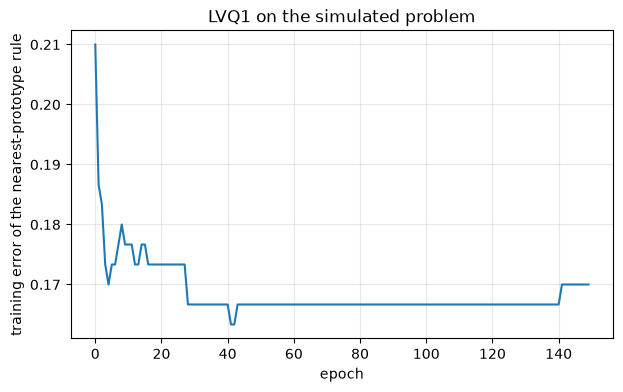

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(errors, color="tab:blue")
ax.set_xlabel("epoch")
ax.set_ylabel("training error of the nearest-prototype rule")
ax.set_title("LVQ1 on the simulated problem")
ax.grid(alpha=0.3);

### Measuring "away from the boundary"

A single number makes the claim checkable: for every prototype, compute the
distance to the nearest prototype of a **different** class, and take the median.
LVQ should increase it, because a prototype that is close to an enemy is the one
the repel step keeps hitting.

In [8]:
def median_gap_to_enemy(protos, pclass):
    d = np.sqrt(((protos[:, None, :] - protos[None, :, :]) ** 2).sum(axis=2))
    d[pclass[:, None] == pclass[None, :]] = np.inf      # ignore same-class pairs
    return np.median(d.min(axis=1))


print(f"median distance to the nearest other-class prototype")
print(f"  before LVQ : {median_gap_to_enemy(protos_km, class_km):.3f}")
print(f"  after  LVQ : {median_gap_to_enemy(protos_lvq, class_lvq):.3f}")

median distance to the nearest other-class prototype
  before LVQ : 0.800
  after  LVQ : 1.493


## 6. Does it help on unseen data?

Prototypes that leave the training points can also leave the *useful* ones, so the
training error alone proves nothing. The honest test is a fresh sample from the
same distribution, which we generated with a different seed.

In [9]:
rows = []
for name, protos, pclass in [
    ("K-means prototypes", protos_km, class_km),
    ("LVQ1 prototypes", protos_lvq, class_lvq),
]:
    rows.append((name, (predict(X_train, protos, pclass) != y_train).mean(),
                 (predict(X_test, protos, pclass) != y_test).mean()))

print(f"{'prototypes':22s}{'train error':>13s}{'test error':>12s}")
for name, tr, te in rows:
    print(f"{name:22s}{tr:13.3f}{te:12.3f}")

prototypes              train error  test error
K-means prototypes            0.240       0.277
LVQ1 prototypes               0.170       0.227


The numbers move by a few points, in the direction the book describes, and the
size of the improvement is itself part of the lesson: LVQ is a **cheap,
local repair** of a K-means solution, not a different model class. Where the
classes are well separated it changes almost nothing; where they overlap, it
redraws the frontier.

## 7. Practical notes

**Initialisation.** ESL starts from the K-means solution, and so should anyone in
practice: starting from random training points leaves far more work for the
online updates. The next cell shows the difference on the same data.

**Learning rate.** `ε_0` sets how far a prototype moves on one observation;
`epochs` sets how long the schedule runs. Too large and the prototypes oscillate,
too small and they never arrive. `ε_t = ε_0/(1+t)` is a safe default.

**`R`, the number of prototypes per class.** More prototypes give a finer
boundary and a larger model; `R = 1` reduces LVQ to a nearest-centroid
classifier, and the update rule to a perceptron-like correction of the centroids.

**Feature scaling.** Euclidean distance is meaningless without it; standardise as
ESL does, with the training statistics.

**Sampling with replacement.** Step 2 draws a random training point every time,
not a pass over a shuffled list, so classes with more points are seen more often.
For imbalanced data that is a bias worth knowing about.

In [10]:
def random_prototypes(X, y, R=5, seed=0):
    rng = np.random.default_rng(seed)
    protos, pclass = [], []
    for k in np.unique(y):
        idx = rng.choice(np.flatnonzero(y == k), size=R, replace=False)
        protos.append(X[idx])
        pclass.append(np.full(R, k))
    return np.vstack(protos), np.concatenate(pclass)


rng_protos, rng_class = random_prototypes(X_train, y_train, R=5)
trials = [
    ("random start, eps0=0.1", rng_protos, rng_class, 0.1),
    ("k-means start, eps0=0.1", protos_km, class_km, 0.1),
    ("k-means start, eps0=0.5", protos_km, class_km, 0.5),
]
for name, p0, c0, eps0 in trials:
    m, c, _ = lvq1(X_train, y_train, p0, c0, eps0=eps0)
    print(f"{name:26s} test error = {(predict(X_test, m, c) != y_test).mean():.3f}")

random start, eps0=0.1     test error = 0.250


k-means start, eps0=0.1    test error = 0.227


k-means start, eps0=0.5    test error = 0.207


## 8. On real data: the iris flowers

Four features, three classes, `R = 3` prototypes per class. With `R` equal to the
class count and well-behaved data the prototypes end up near the class means, so
LVQ has little to repair — which is exactly why the simulated problem above was
needed to see the effect.

In [11]:
iris = load_iris()
Xi, yi = iris.data, iris.target
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, test_size=0.3, random_state=0, stratify=yi)
Xi_train, Xi_test = standardize(Xi_train, Xi_test)

p0, c0 = kmeans_prototypes(Xi_train, yi_train, R=3)
m_i, c_i, _ = lvq1(Xi_train, yi_train, p0, c0, epochs=100)

centroids = np.vstack([Xi_train[yi_train == k].mean(axis=0) for k in range(3)])
for name, protos, pclass in [
    ("nearest centroid (R=1)", centroids, np.arange(3)),
    ("K-means prototypes (R=3)", p0, c0),
    ("LVQ1 prototypes (R=3)", m_i, c_i),
]:
    te = (predict(Xi_test, protos, pclass) != yi_test).mean()
    print(f"{name:26s} test error = {te:.3f}")

nearest centroid (R=1)     test error = 0.244
K-means prototypes (R=3)   test error = 0.000
LVQ1 prototypes (R=3)      test error = 0.000


## 9. Where the name comes from: vector quantization

"Quantization" is the older idea behind the method: replace a vector by the
**index of the nearest prototype** and store only that index. With `K` prototypes
each index costs `log2(K)` bits instead of the bits of a whole vector, so the
prototype set becomes a **codebook** and the method becomes lossy compression.

Applied to image blocks instead of feature vectors, this is plain K-means on
`4 x 4` blocks of the coffee photograph: 16 pixels become one 4-bit index, a
factor 32 in storage, at the price of a small reconstruction error. (This is the
material of ESL §14.3.9; it is kept here because it explains the name.)

blocks: (15000, 16)


prototypes in the codebook : 16, 4 bits per block
bits per pixel            : 0.250 instead of 8
PSNR                      : 24.80 dB


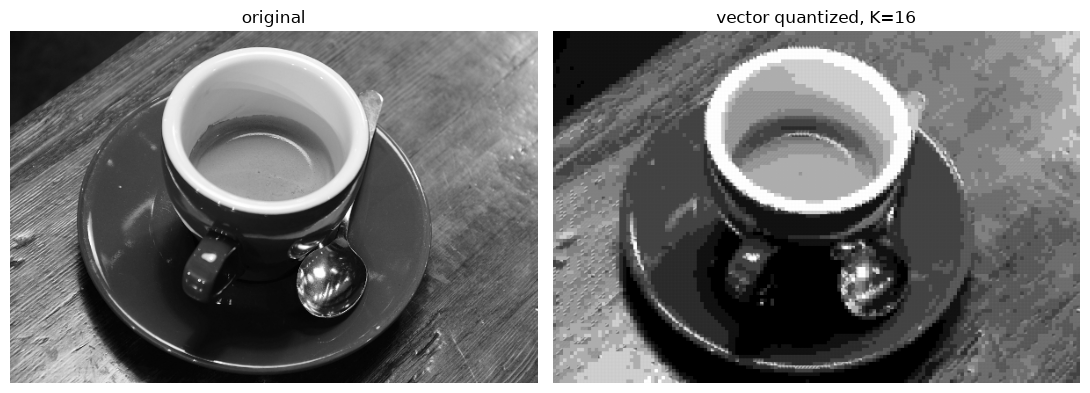

In [12]:
img = rgb2gray(data.coffee())          # 400 x 600, one gray level per pixel
bs, K_vq = 4, 16
blocks = view_as_blocks(img, (bs, bs)).reshape(-1, bs * bs)
print("blocks:", blocks.shape)

codebook = KMeans(n_clusters=K_vq, n_init=10, random_state=0).fit(blocks)
labels = codebook.labels_
rec = codebook.cluster_centers_[labels].reshape(img.shape[0] // bs,
                                                img.shape[1] // bs, bs, bs)
rec = rec.transpose(0, 2, 1, 3).reshape(img.shape)

mse = ((img - rec) ** 2).mean()
print(f"prototypes in the codebook : {K_vq}, {np.log2(K_vq):.0f} bits per block")
print(f"bits per pixel            : {np.log2(K_vq) / (bs * bs):.3f} instead of 8")
print(f"PSNR                      : {10 * np.log10(1.0 / mse):.2f} dB")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("original")
axes[1].imshow(rec, cmap="gray"); axes[1].set_title(f"vector quantized, K={K_vq}")
for a in axes:
    a.axis("off")
plt.tight_layout();

## Summary

* A prototype method classifies by the label of the closest prototype;
  `K*R` prototypes encode a curved decision boundary.
* Clustering each class on its own (§13.2.1) puts prototypes where that class is
  dense, with no regard for the others, so they drift onto the boundaries — the
  shortcoming the book names explicitly.
* LVQ (§13.2.2) is online and label-aware: the point attracts the closest
  prototype of its own class and repels the closest prototype of another class,
  with a step `ε` that decays to zero.
* This is LVQ1; LVQ2, LVQ3 extend it, and the family has **no fixed objective
  function** — that is the method's price.
* Starting from the K-means prototypes (ESL's choice) is far better than starting
  from random points, and the effect of LVQ is a local repair of the boundary.
* The same "nearest prototype + store the index" idea, applied to image blocks,
  is vector quantization: the origin of the name.

## Exercises

1. Set `R = 1` and run LVQ on the simulated data. What does the update rule
   become, and why does the boundary stay almost straight?
2. Replace the schedule `ε_t = ε_0/(1+t)` by a constant `ε = 0.1`. Plot the
   training error against the epoch: what do you see, and which of the three
   stochastic-approximation conditions is violated?
3. Use `R = 2, 5, 10, 20` prototypes per class and plot the test error. Where
   does the curve flatten, and what is the cost per prototype?
4. Attract-only variant: delete the repel branch and train from the K-means
   start. Explain the result in terms of the book's sentence about who has a
   say in the placement of prototypes.
5. Calculate the Bayes error of the simulated problem analytically (or estimate
   it with a very large 1-NN model) and compare it with the errors of the two
   prototype sets.
6. For the compression experiment, try `bs = 2` and `bs = 8` with the same number
   of bits per pixel. Which block size gives the better picture, and why is tile
   structure visible in the reconstruction?

## Sources

* The method, its algorithm (Algorithm 13.1) and the simulated example:
  §13.2.2 and §13.2 of {cite}`hastie2009esl` (2nd edition, pp. 461–463); the
  compression experiment follows §14.3.9 of the same book. Figures on this page
  are generated by the code above, reproducing the comparison of ESL Figure 13.1.
* Kohonen's original LVQ papers are the references given there; the GLVQ
  reformulation is the cost-function-based repair of the "no fixed criterion"
  objection.
* `sklearn.cluster.KMeans` documentation for the implementation used to build
  the initial prototypes.